# BEE 4750 Homework 5: Gaussian Plumes and Model Validation

**Name**: Anthony Santos

**ID**: acs367

> **Due Date**
>
> Thursday, 10/22/26, 9:00pm

## Overview

### Instructions

- Problem 1 asks you to evaluate the plume equation and reason about
  stability class.
- Problem 2 asks you to analyze residuals to interpret goodness-of-fit.
- Problem 3 asks you to calibrate a working plume model against a set of
  monitor observations and decide whether it is the right model for the
  setting.

### Load Environment

In [4]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()


Pkg.add(["CSV", "DataFrames", "Optim", "Plots"])   # Statistics is built in

  Activating project at `c:\Users\thean\Downloads\BEE 4750\HW5\hw05`
   Installed SentinelArrays ───── v1.4.8
   Installed GR_jll ───────────── v0.73.18+0
   Installed Pango_jll ────────── v1.57.0+0
   Installed PlotUtils ────────── v1.4.4
   Installed OpenSSL ──────────── v1.6.0
   Installed JSON ─────────────── v1.3.0
   Installed DataFrames ───────── v1.8.1
   Installed CSV ──────────────── v0.10.17
   Installed Crayons ──────────── v4.1.1
   Installed StatsBase ────────── v0.34.8
   Installed StableRNGs ───────── v1.0.4
   Installed Adapt ────────────── v4.7.1
   Installed DataStructures ───── v0.19.3
   Installed FFMPEG_jll ───────── v8.0.0+0
   Installed Tables ───────────── v1.12.1
   Installed PrettyTables ─────── v3.1.0
   Installed StringManipulation ─ v0.4.1
   Installed StructUtils ──────── v2.6.0
   Installed GR ───────────────── v0.73.18
Precompiling project...
   6188.0 ms  ✓ WorkerUtilities
   3384.3 ms  ✓ StableRNGs
   3369.6 ms  ✓ InlineStrings
   3355.7 ms  ✓ Adapt
 

In [3]:
@show @__DIR__
@show pwd()
@show isfile(joinpath(@__DIR__, "Project.toml"))
@show isfile(joinpath(pwd(), "Project.toml"))

#= c:\Users\thean\Downloads\BEE 4750\HW5\hw05\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W2sZmlsZQ==.jl:1 =# @__DIR__() = "c:\\Users\\thean\\Downloads\\BEE 4750\\HW5\\hw05"
pwd() = "c:\\Users\\thean\\Downloads\\BEE 4750\\HW5\\hw05"
isfile(joinpath(#= c:\Users\thean\Downloads\BEE 4750\HW5\hw05\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W2sZmlsZQ==.jl:3 =# @__DIR__(), "Project.toml")) = true
isfile(joinpath(pwd(), "Project.toml")) = true


true

In [6]:
using CSV
using DataFrames
using Statistics
using Optim
using Plots

## Problems (Total: 50 Points)

### Problem 1 (10)

The ground-level concentration downwind of an elevated point source, on
the plume centreline and accounting for reflection at the ground, is

$$C(x, y) = \frac{Q}{\pi u \sigma_y(x) \sigma_z(x)} \exp\left(\frac{-y^2}{2\sigma_y(x)^2}\right)\exp\left(\frac{-H^2}{2\sigma_z(x)^2}\right).$$

A stack emits $Q = 100$ g/s at an effective height of $H = 41$ m into a
wind of $u = 2.5$ m/s.

#### Problem 1.1 (5)

At 2 km downwind under the stability class in question, $\sigma_y = 62$
m and $\sigma_z = 23$ m.

1.  Compute the ground-level concentration on the centreline at 2 km, in
    µg/m³.
2.  Compute it again at a receptor 60 m off the centreline at the same
    distance. What fraction of the centreline value is it?

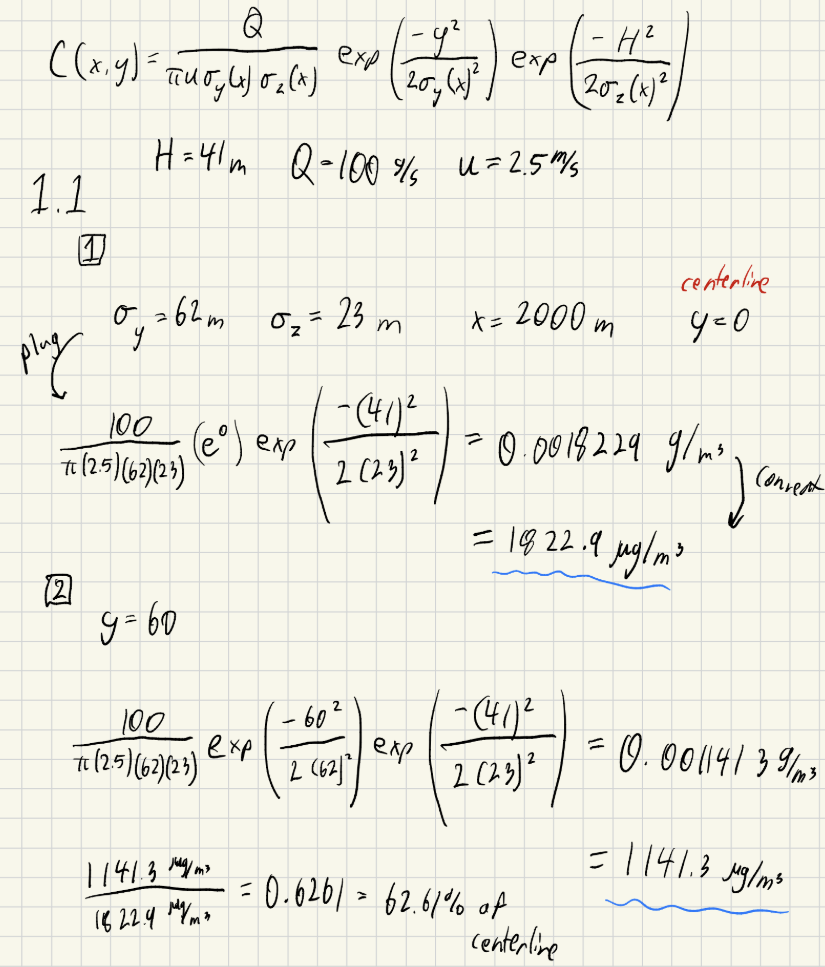



#### Problem 1.2 (5)

Stability classes run from A (very unstable, strong daytime heating)
through F (stable, clear calm night). In lecture, this same stack
produced a higher ground-level peak under class B (a sunny afternoon)
than under class F (a clear night), much closer to the stack. The
dispersion coefficients at two distances downwind are:

| Distance | Class B: $\sigma_y$, $\sigma_z$ (m) | Class F: $\sigma_y$, $\sigma_z$ (m) |
|:-----------------------|-----------------------:|-----------------------:|
| 1 km | 156, 110 | 34, 14 |
| 8 km | 1001, 1064 | 218, 42 |

A school sits 1 km directly downwind of the stack, and a town 8 km
downwind. The 1-hour SO$_2$ standard is 196 µg/m³.

1.  Compute the ground-level centreline concentration at the school and
    at the town under each class. Which class is the worst case at each
    receptor?
2.  The facility’s consultant proposes a permit analysis that models
    only class B, since it produces the highest peak. What would that
    analysis miss? Which conditions should a permit analysis model
    instead? Use your table to say why.

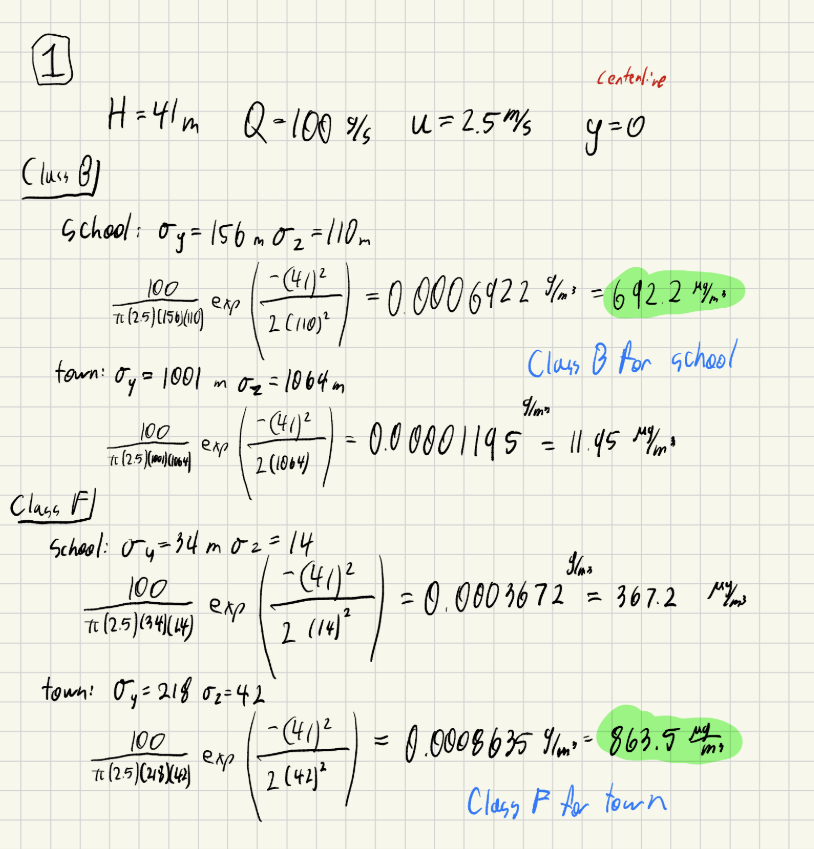


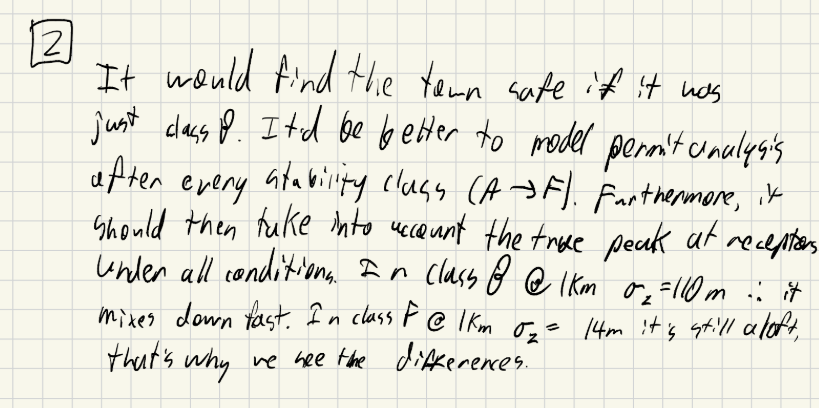


### Problem 2 (5)

A dissolved-oxygen model is compared with measurements at six stations
along a river, numbered in order downstream. Three versions of the model
leave these residuals (model minus observation, in mg/L):

| Station |    1 |    2 |    3 |    4 |    5 |    6 |
|:--------|-----:|-----:|-----:|-----:|-----:|-----:|
| Model A | +0.7 | −0.5 | −0.1 | +0.5 | −0.7 | +0.1 |
| Model B | +0.5 | +0.5 | +0.5 | +0.5 | +0.5 | +0.5 |
| Model C | −0.7 | −0.5 | −0.1 | +0.1 | +0.5 | +0.7 |

#### Problem 2.1 (1)

Compute the RMSE of each model.


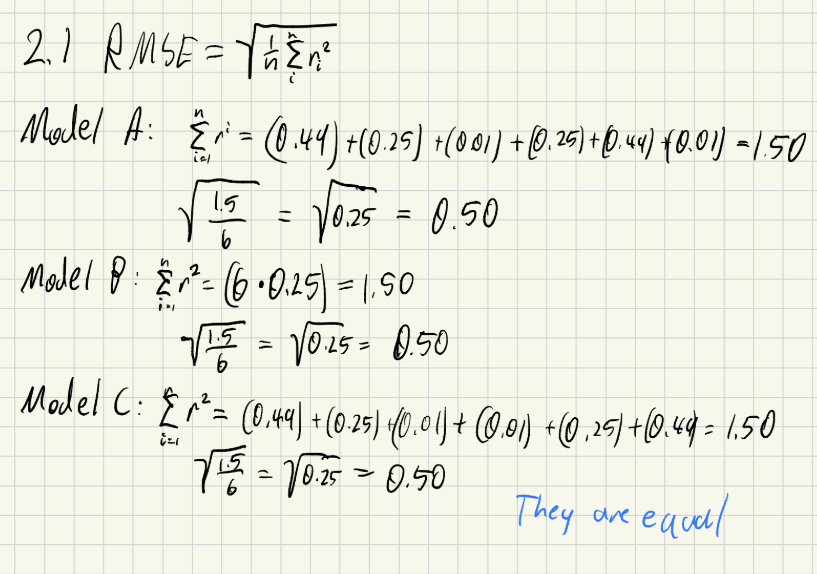



#### Problem 2.2 (3)

For each model, say in a sentence what its residuals show that the RMSE
does not, and what kind of error that suggests.

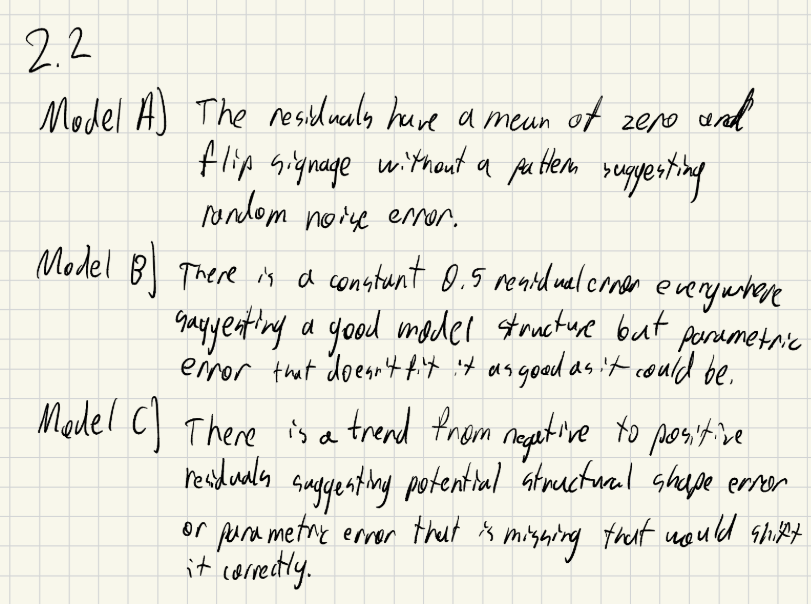


#### Problem 2.3 (1)

A parameter that shifts every prediction up or down by the same amount
(for example, a sensor’s calibration offset) is changed until the fit is
as good as it can be. Which model or models could that fix?

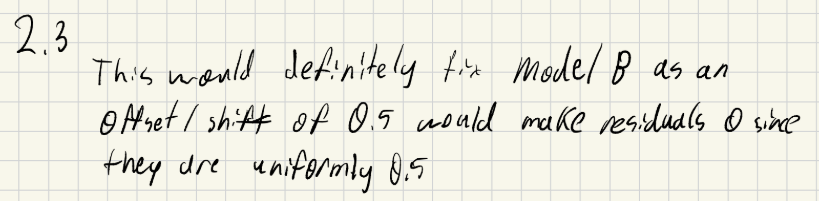





### Problem 3 (35)

A smelter sits on the floor of a narrow valley that runs east–west. One
clear night there was almost no wind, and a **temperature inversion**
formed over the valley floor.

Air normally gets colder with height, so air warmed near the ground
rises and carries pollution up and away. On a clear, calm night the
ground cools quickly and chills the air just above it, which leaves a
pool of cold air sitting under warmer air. This is called an
**inversion**. The cold air is heavier than the air above it and cannot
rise, so the warmer air acts as a lid. That night the smelter’s $SO_2$
stayed in the pool of cold air on the valley floor. With almost no wind
to carry it out of the valley, its concentration built up through the
night.

The facility’s anemometer averaged 1 m/s from the west over the night,
but the wind was light and swung through every direction.

Twelve monitors on the valley floor recorded the night’s average $SO_2$
concentration. Their readings are in `data/receptors.csv`, with
positions measured from the stack: `downwind_km` is the distance east of
the stack (negative values are west of it), and `crosswind_m` is the
distance north.

The facility’s consultant modelled the night with the Gaussian plume
model below, using stability class F and the night’s average wind, 1 m/s
from the west. The stack’s effective height, 41 m including plume rise,
is known. Your job is to decide whether that model is fit to be used.

The stability classes run from A (strong daytime heating) through D
(neutral: overcast or windy) to F (a clear, calm night).

In [7]:
# Pasquill-Gifford coefficients for each stability class. Distances in km,
# sigmas in metres.
stability_coefs = Dict(
    "A" => (; a=213, c_near=440.8, d_near=1.941, f_near=9.27,
              c_far=459.7, d_far=2.094, f_far=-9.6),
    "B" => (; a=156, c_near=106.6, d_near=1.149, f_near=3.3,
              c_far=108.2, d_far=1.098, f_far=2),
    "C" => (; a=104, c_near=61, d_near=0.911, f_near=0,
              c_far=61, d_far=0.911, f_far=0),
    "D" => (; a=68, c_near=33.2, d_near=0.725, f_near=-1.7,
              c_far=44.5, d_far=0.516, f_far=-13),
    "E" => (; a=50.5, c_near=22.8, d_near=0.678, f_near=-1.3,
              c_far=55.4, d_far=0.305, f_far=-34),
    "F" => (; a=34, c_near=14.35, d_near=0.740, f_near=-0.35,
              c_far=62.6, d_far=0.180, f_far=-48.6))
class_names = ["A", "B", "C", "D", "E", "F"]

sigma_y(downwind_km, coef) = coef.a * downwind_km^0.894

function sigma_z(downwind_km, coef)
    if downwind_km < 1
        return coef.c_near * downwind_km^coef.d_near + coef.f_near
    else
        return coef.c_far * downwind_km^coef.d_far + coef.f_far
    end
end

# Ground-level concentration [µg/m³]. The wind blows along the downwind axis,
# so the model puts nothing upwind of the stack.
function ground_concentration(downwind_km, crosswind_m, coef;
                              emission=100, height=41, wind=1)
    if downwind_km <= 0.05
        return 0.0
    end
    spread_y = sigma_y(downwind_km, coef)
    spread_z = sigma_z(downwind_km, coef)
    if spread_z <= 0
        return 0.0
    end
    return (emission / (π * wind * spread_y * spread_z)) *
        exp(-crosswind_m^2 / (2 * spread_y^2)) *
        exp(-height^2 / (2 * spread_z^2)) * 1e6
end

monitors = CSV.read(joinpath(@__DIR__, "data", "receptors.csv"), DataFrame)

Row,monitor,downwind_km,crosswind_m,observed_ugm3
,DataStri…,Float64,Int64,Float64
1,M01,-3.2,150,2648.3
2,M02,-2.4,-100,2410.3
3,M03,-1.8,0,2676.4
4,M04,-1.2,200,2085.3
5,M05,-0.6,-50,2558.8
6,M06,0.5,0,2509.4
7,M07,0.9,100,2540.5
8,M08,1.5,-150,2473.9
9,M09,2.0,0,2448.8


#### Problem 3.1 (6)

Run the consultant’s model (class F, 1 m/s) at each monitor and compute
the RMSE against the observations. Report it both in µg/m³ and as a
percentage of the mean observed concentration.

On that number alone, would you say the model fits?


In [ ]:

coefF = stability_coefs["F"] # Class F stability coefficients
obs = monitors.observed_ugm3

model = [ground_concentration(r.downwind_km, r.crosswind_m, coefF, emission=100, height=41, wind=1) for r in eachrow(monitors)]
residuals = obs .- model
rmse = sqrt(mean(residuals .^ 2))
meanobs = mean(obs)

println(model)
println("RMSE for stability class F: ", round(rmse, digits=1), " µg/m³")
println("RMSE as % of mean observed: ", round(rmse / meanobs * 100, digits=1), "%")

[0.0, 0.0, 0.0, 0.0, 0.0, 0.8930009781629029, 2.802633287523946, 28.49027361557603, 4176.14683558986, 189.6542737850049, 2410.280281783393, 3708.61645398121]RMSE for stability class F: 7560.312479946277
Percentage of mean observed concentration: 34.68080169702927%



#### Problem 3.2 (9)

Wind speed is the most uncertain input here, and the whole concentration
field scales as $1/u$. It is the obvious thing to calibrate.

Keeping class F, fit the wind speed by minimising RMSE against the
observations. Search between 0.3 and 20 m/s.

1.  Report the fitted wind speed to the nearest 0.1 m/s and the RMSE
    after calibration.
2.  Did calibration meaningfully improve the fit?
3.  Explain the result in terms of what wind speed *can* and *cannot*
    change about the modelled field.

In [32]:
function model_rmse(coef, wind_speed)
    model = [ground_concentration(r.downwind_km, r.crosswind_m, coef, emission=100, height=41, wind=wind_speed) for r in eachrow(monitors)]
    return sqrt(mean((model .- monitors.observed_ugm3) .^ 2))
end

res = Optim.optimize(u -> model_rmse(stability_coefs["F"], u), 0.3, 20.0)
u_fit = Optim.minimizer(res)
rmse_fit = Optim.minimum(res)

println("Fitted wind: ", round(u_fit, digits=1), " m/s")
println("RMSE at u = 1:   ", round(model_rmse(stability_coefs["F"], 1.0), digits=2), " µg/m³")
println("RMSE calibrated: ", round(rmse_fit, digits=2), " µg/m³")

Fitted wind: 1.3 m/s
RMSE at u = 1:   2182.47 µg/m³
RMSE calibrated: 2145.44 µg/m³


> **One-variable search in Optim**
>
> `Optim.optimize(f, lower, upper)` minimises a function `f` of one
> number between two bounds. Here `f` can be
> `u -> model_rmse(stability_coefs["F"], u)`. `Optim.minimizer` returns
> the best value found and `Optim.minimum` the function’s value there.

#### Problem 3.3 (10)

Stability class is the other input the consultant chose. Calibrate it as
well: for each of the six classes, fit the wind speed as in Problem 3.2.

1.  Report the fitted wind speed and the RMSE for each class in a table.
    Which class fits best, and what is its RMSE as a percentage of the
    mean observed concentration?
2.  For that best fit, list the modelled and observed concentrations at
    each monitor. At which monitors can no wind speed or stability class
    bring the model close to the observation, and why?
3.  Was class F the wrong choice for this night? Answer from the
    conditions each class describes, not from the RMSE.

In [28]:
for cls in class_names # Iterate through stability classes
    coef = stability_coefs[cls] # current stability coef
    res = Optim.optimize(u -> model_rmse(coef, u), 0.3, 20.0) # Minimize RMSE for the current stability class
    u_best = Optim.minimizer(res) # Return the wind speed that mins RMSE
    rmse_best = Optim.minimum(res) # Return the min RMSE val
    percentage = 100 * rmse_best / mean_obs # Calculate percentage of RMSE to mean observed
    push!(results, (cls, round(u_best, digits=1), rmse_best, percentage)) # Add to table
end
print(results)

println()
println("==========================================")
println("Best fit for stability class D")

bestfitresults = DataFrame(Monitor=String[], downwindkm=Float64[], crosswindm=Float64[], modelled=Float64[], observed=Float64[])
CoefD = stability_coefs["D"]
res2 = Optim.optimize(u -> model_rmse(CoefD, u), 0.3, 20.0) # Minimize RMSE for the current stability class
u_best2 = Optim.minimizer(res2) # Return the wind speed that mins RMSE

for row in eachrow(monitors) # Initiate for loop to iterate through data to calculate predictions
    predictedbestfit = ground_concentration(row.downwind_km, row.crosswind_m, CoefD, emission=100, height=41, wind=u_best2)
    push!(bestfitresults, (row.monitor, row.downwind_km, row.crosswind_m, round(predictedbestfit, digits=1), row.observed))
end
print(bestfitresults)

UndefVarError: UndefVarError: `mean_obs` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

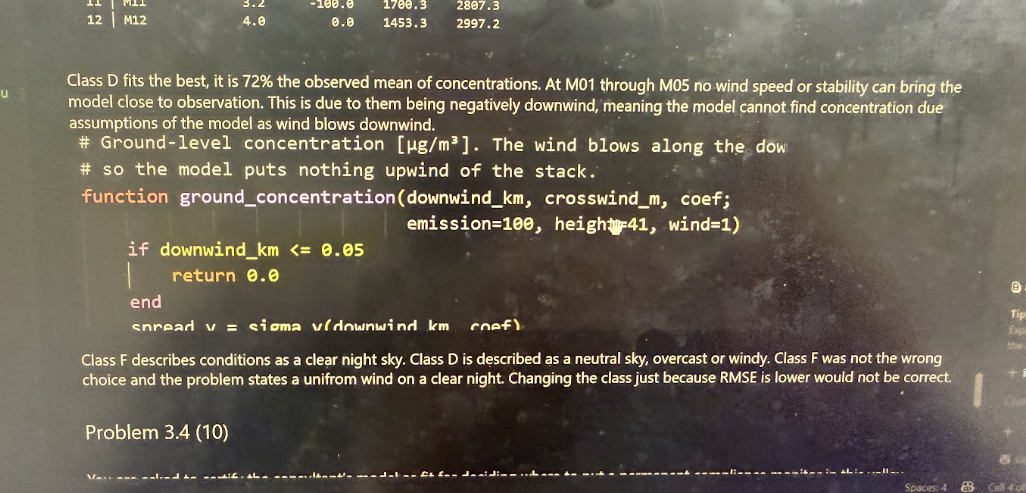

I unfortunately deleted a past version but managed to take a photo before I deleted of my answer to this, apologies for quality.


#### Problem 3.4 (10)

You are asked to certify the consultant’s model as fit for deciding
where to put a permanent compliance monitor in this valley.

1.  Would you certify it? State your decision plainly.
2.  Which assumptions of the plume model do not hold on a night like
    this one? Name two, and tie each to something in the setting or in
    your results.
3.  The consultant replies that the model has now been calibrated, so it
    is “as good as it can be.” Respond to that argument.


1. No I would not certify the model. RMSE is huge for all the best fits and a large percentage of the observed values. Even with the best class it is 72% of the observed values.

2. The wind should be in a single direction with a set velocity the whole night for the model. In the problem statement it said the wind was from the west and was swirling. The model discounted this, meaning concentration could not be detected at negative distance downwind. It assumed 1-D wind which isn't correct. Furthermore, there should be more vertical mixing, it shouldn't be limited by a thermal inversion. There should likely be another term like the floor term that "bounces" the plume back. The plume is slightly uniform everywhere with observed values varying slightly from 2000-3000.

3. This is false. Sure, it can be calibrated to the point of fitting a model well but "as good as it can be" is an argument for the use of a whole different model. That's saying this model has reached its level of correctness, and that level is not that accurate. RMSE values do not lie and assumptions of the model has been violated.



## References

List any external references consulted, including classmates.